# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

__DIAGNÓSTICO:__
- churn_date contiene 88.35% de valores nulos, pero al identificarse como la fecha de cancelación de servicio, este valor dice que esa cantidad de clientes siguen activos
- city cuenta con una proporción del 11.725% de datos nulos, lo que indica un error de captura durante el proceso, estos pueden guardarse como "desconocido" para mantener los datos
- En el dataframe de Usage, duration y length contienen el 55.19% y 44.74% de valores nulos, sin embargo, al revisar las columnas se deduce que esto se debe e que los valores con duration ausente son por ser textos, y viceversa con length al ser llamadas
- Para la columna de date con un error de captura de 0.125% se pueden imputar los registros 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users

col_num_users = ["age", "user_id"]
users[col_num_users].describe()


,age,user_id
count,4000.000000,4000.000000
mean,33.739750,11999.500000
std,123.232257,1154.844867
min,-999.000000,10000.000000
25%,32.000000,10999.750000
50%,47.000000,11999.500000
75%,63.000000,12999.250000
max,79.000000,13999.000000


- La columna `user_id`: Los valores no dicen mucho pues es una variable de identificación sin aporte estadístivo cuantitativo
- La columna `age`: cuenta con un valor mínimo erróneo de -999 lo que indica imputación errónea, lo que causa que la media se vea afectada hacia abajo e incrementa artificialmente la desviación estándar

In [13]:
# explorar columnas numéricas de usage
col_num_usage = ["duration", "length", "id", "user_id"]
usage[col_num_usage].describe()

,duration,length,id,user_id
count,17924.000000,22104.000000,40000.00000,40000.000000
mean,5.202237,52.127398,20000.50000,12002.405975
std,6.842701,56.611183,11547.14972,1157.279564
min,0.000000,0.000000,1.00000,10000.000000
25%,1.437500,37.000000,10000.75000,10996.000000
50%,3.500000,50.000000,20000.50000,12013.000000
75%,6.990000,64.000000,30000.25000,13005.000000
max,120.000000,1490.000000,40000.00000,13999.000000


- Las columnas `id` y `user_id`: no aportan valor estadístico cuantitativo para este caso
- Las columnas `duration` y `length`: cuentan con valores aunque altos son plausibles para la clasificación. Por otra parte la mínima se debe a lo que se mencionó anteriormente sobre como el registro de length o duration es nulo para texto o llamada, según sea el caso, porque no le aplica

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city`: Bogotá es el de mayor número de usuarios por ciudad. En el conteo aparecen los datos faltantes revisados anteriormente (469 nulos) 
- La columna `plan`: Hay una preferencia por el plan básico con un 64.88% del total de clientes registrados

In [15]:
# explorar columna categórica de usage
columnas_usage = ['type']
usage[columnas_usage].describe()

,type
count,40000
unique,2
top,text
freq,22092


- La columna `type`: Es preferido el mensaje de texto abarcando el 55.23% del tráfico total


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
en la columna de age y date
- ¿Qué acción tomarías?
    *Tratar los sentinels de edad
    *Categorizar ("desconocido") los valores nulos en city para no perder 12% de datos
    *Tratar los registros de call y text con filtros para verificar que los datos en 0 se deben a que "no aplica", o si son datos en 0 como llamadas perdidas o textos sin caracteres
    *Convertir los identificadores a strings

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"],errors="coerce")

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"],errors="coerce")

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False)

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`: el registro por año es estable, y del año 2026 hay pocos datos al ser un año en transcurso. Tampoco hay registros en 2025

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False)

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`: los registros son únicamente del año 2024,aunque haya registro de usuarios, esto puede indicar que el dataset de uso es solo una cohorte de este año.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
No hay registros del año 2025, los valores bajos de 2026 pueden deberse a que no ha transcurrido el año al completo.
- ¿Qué harías con ellas?
Complementar los datos de usage con la cohorte correspondiente a ese año, el que solo haya registros de 2024 indica que este dataset solo comprende valores de dicho año, y descartaría los 50 valores NaN que aparecen, evaluando únicamente valores válidos y de la cohorte del año que se tienen registros

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users["age"].replace(-999, np.nan).fillna(age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", "NA")

# Verificar cambios
users["city"].unique()

array(['Medellín', 'NA', 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [22]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
users['reg_date'] = users['reg_date'].mask(users['reg_date'] > pd.Timestamp.now())

# Verificar cambios
users['reg_date'].dtype

dtype('<M8[ns]')

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration_is_null'] = usage['duration'].isna()

duration_mar = pd.crosstab(
    usage['type'], 
    usage['duration_is_null'], 
    normalize='index'
) * 100

print("VERIFICACIÓN MAR:")
print(duration_mar.round())

VERIFICACIÓN MAR:
duration_is_null  False  True 
type                          
call              100.0    0.0
text                0.0  100.0


In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length_is_null'] = usage['length'].isna()

length_mar = pd.crosstab(
    usage['type'], 
    usage['length_is_null'], 
    normalize='index'
) * 100

print("VERIFICACIÓN MAR")
print(length_mar.round())

VERIFICACIÓN MAR
length_is_null  False  True 
type                        
call              0.0  100.0
text            100.0    0.0


Diagnostico de nulos en `duration` y `length`
Las tablas muestran una dependencia absoluta entre el evento y los valores nulos, por lo que la razón por la que falte un dato se explica por la otra, es decir, no se perdieron datos o haya errores. Por lo que se deben mantener como están. 


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_user = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_user.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_user = usage_user.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_user.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios

user_profile = pd.merge(users, usage_user, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024


🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.


In [28]:
# Resumen estadístico de las columnas numéricas
cols_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

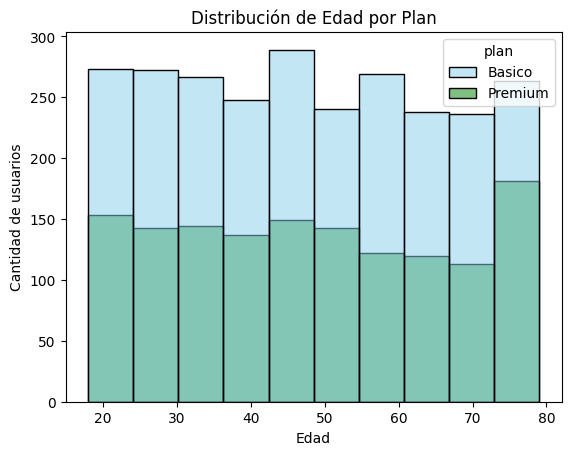

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile[user_profile['age'] > 0], bins=10, x="age", hue="plan", palette=['skyblue', 'green'])
plt.xlabel("Edad")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de Edad por Plan")
plt.show()

💡Insights: 
- Distribución: excluyendo los outliers de -999 de edad, la edad va desde los 18-80 aprox.  con una distribución prácticamente uniforme entre las edades, hay un predominio del plan básico y esta proporción casi 2:1 se mantiene, con una reducción aparente en la edad más avanzada

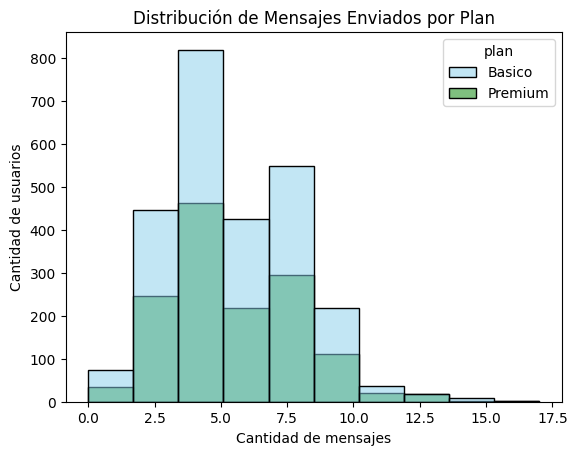

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile[user_profile['age'] > 0], 
    bins=10, 
    x="cant_mensajes", 
    hue="plan", 
    palette=['skyblue', 'green']
)
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de Mensajes Enviados por Plan")
plt.show()

💡Insights: 
- Aquí se puede observar un sesgo a la derecha, con la mayoría de los usuarios enviando un bajo número de mensajes, el plan básico sobresale por cantidad de mensajes pero se mantiene una distribución equivalente, indicando que los hábitos de mensajes siguen el mismo patrón indistinto del plan contratado.

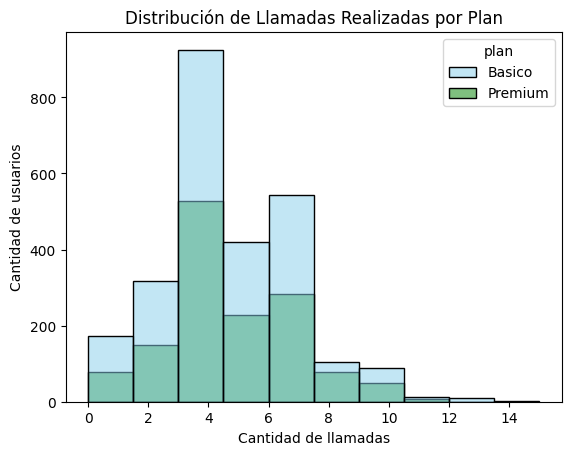

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile[user_profile['age'] > 0], 
    bins=10, 
    x="cant_llamadas", 
    hue="plan", 
    palette=['skyblue', 'green']
)
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de Llamadas Realizadas por Plan")
plt.show()

💡Insights: 
- Distribución con sesgo a la derecha, se mantiene por llamadas la dominancia de planes básicos, pero conforme aumenta la cantidad de llamadas se acerca más la cantidad de usuarios premium 

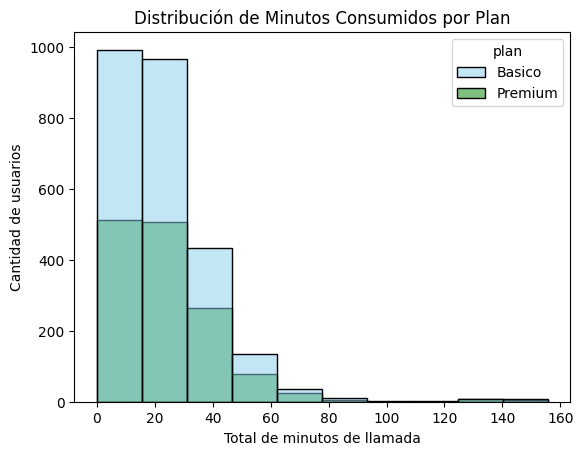

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile[user_profile['age'] > 0], 
    bins=10, 
    x="cant_minutos_llamada", 
    hue="plan", 
    palette=['skyblue', 'green']
)
plt.xlabel("Total de minutos de llamada")
plt.ylabel("Cantidad de usuarios")
plt.title("Distribución de Minutos Consumidos por Plan")
plt.show()

💡Insights: 
- Completamente sesgado a la derecha con dominio del plan básico y un patrón de uso idéntico, con acercamiento de usuarios entre más minutos de llamada hay (lo cual tiene sentido con el histograma de llamadas)

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

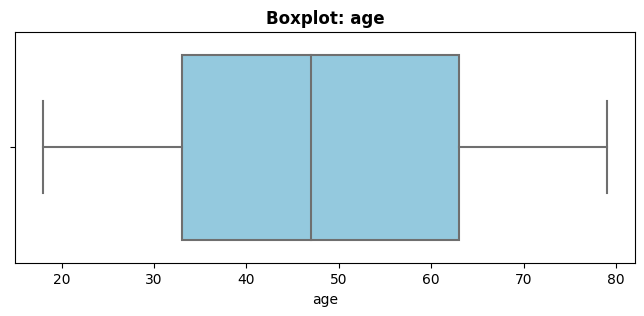

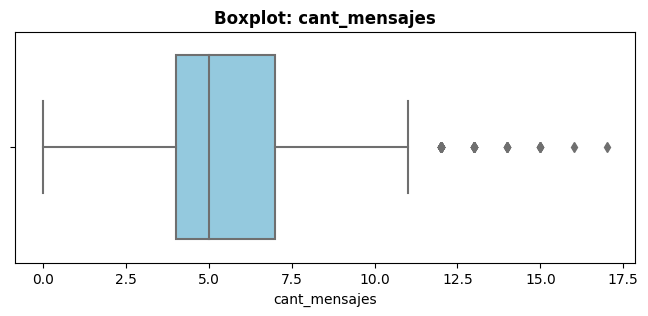

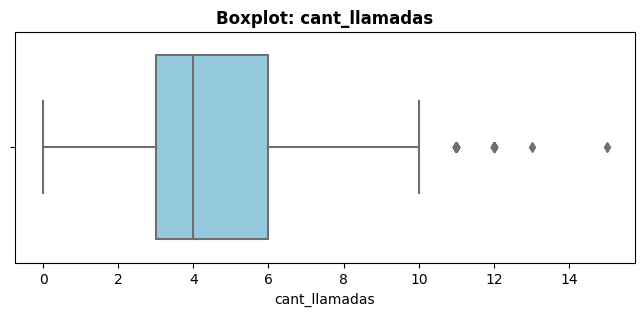

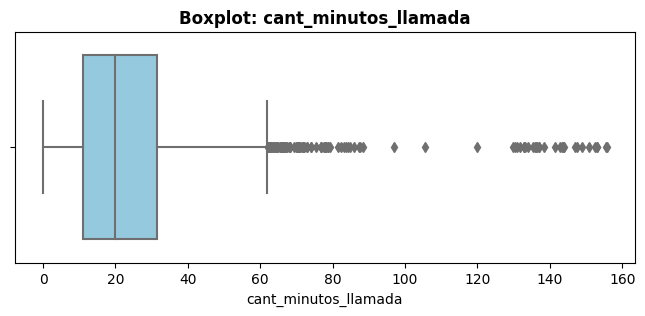

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: presenta los outliers mencionados de -999
- cant_mensajes: Presenta outliers superiores a partir de los 11 mensajes aprox. y una concentración de datos en los 5 mensajes enviados
- cant_llamadas: Presenta outliers superiores en la cantidad de llamadas, con puntos aislados a partir de las 10 llamadas, el 50% de los usuarios realiza de 3 a 6 llamadas, con una mediana de 4 llamadas
- cant_minutos_llamada: Es el gráfico con mayor número de outliers, al tenerlos a partir de los 60mins de llamada, cuenta con una mediana de 20 y una concentración de datos entre los 10-30 minutos de llamada

In [35]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[col].describe()

count    3999.000000
mean       23.317054
std        18.168095
min         0.000000
25%        11.120000
50%        19.780000
75%        31.415000
max       155.690000
Name: cant_minutos_llamada, dtype: float64

💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?Mantener
Porque representa un comportamiento real de uso en plataformas de mensajería, donde una minoría de usuarios intensivos (heavy users) envía un volumen muy superior al promedio. Mantener estos datos es clave para evaluar si estos usuarios se benefician de paquetes o tarifas planas en sus planes.
- cant_llamadas: mantener o no outliers, porqué? Mantener
Porque las llamadas también presentan una distribución sesgada hacia la derecha natural en servicios de telecomunicaciones. Los valores altos no corresponden a un error de medición ni a un fallo del sistema, sino a patrones de consumo reales que ayudan a segmentar correctamente la cartera de clientes.
- cant_minutos_llamada: mantener o no outliers, porqué?Mantener
Porque aunque el valor máximo supera ampliamente el límite superior del IQR y el percentil 75%, 155 minutos en un período de facturación es una cifra completamente coherente e instructiva. Eliminar o recortar (capping) estos valores distorsionaría el análisis de ingresos operacionales e invisibilizaría a los clientes con mayor consumo.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [43]:
# Crear columna grupo_uso
def clasificar_uso(row):
    if row['cant_llamadas'] < 5:
        if row['cant_mensajes'] < 5:
            return 'Bajo uso'
        elif row['cant_mensajes'] < 10:
            return 'Uso medio'
        else:
            return 'Alto uso'
    elif row['cant_llamadas'] < 10:
        if row['cant_mensajes'] < 10:
            return 'Uso medio'
        else:
            return 'Alto uso'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [42]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad
def clasificar_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

# Crear la columna grupo_edad en user_profile
user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

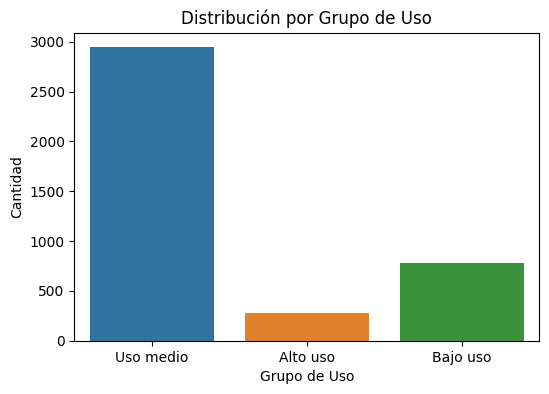

In [52]:
# Visualización de los segmentos por uso

plt.figure(figsize=(6, 4))
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Distribución por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad')
plt.show()

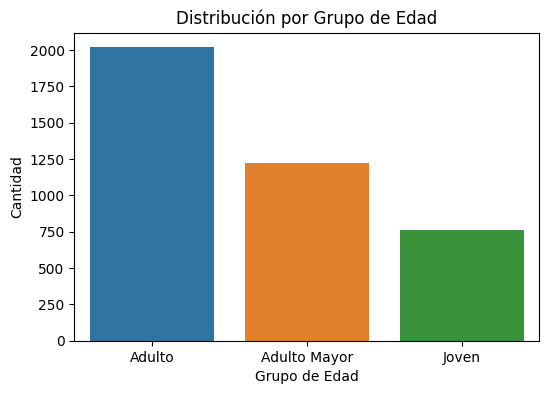

In [48]:
# Visualización de los segmentos por edad
plt.figure(figsize=(6, 4))
sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Distribución por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Presencia de valores atípicos en los datos, ejemplo los outliers de age
- No todos los datos estaban completos, ni se tenía el 100% de registros confiables


🔍 **Segmentos por Edad**
- Adulto: Es el segmento demográfico dominante en la plataforma, representando más del 50% de la base total.
- Adulto Mayor: Ocupa el segundo lugar en volumen (aproximadamente el 30%), mostrando una presencia relevante dentro del parque de clientes.
- Joven: Constituye el grupo demográfico menor (aproximadamente el 19%).   


📊 **Segmentos por Nivel de Uso**
- Uso medio: Constituye la gran mayoría de la base de clientes (aproximadamente el 74%). Mantienen un consumo moderado y regular de llamadas y mensajes
- Bajo uso: Representa el segundo grupo más numeroso (aproximadamente el 20%). Tienen requerimientos mínimos de comunicación (menos de 5 llamadas y mensajes)
- Alto uso: Es un segmento de nicho (aproximadamente el 6%). Aunque es el grupo más reducido, concentra la mayor intensidad de interacción en la red


➡️ Esto sugiere que ...
el modelo de negocio de ConnectaTel descansa principalmente en una base de clientes madura (los segmentos "Adulto" y "Adulto Mayor" representan más del 80% de la población) y de consumo moderado (~74% en "Uso medio"), por lo que cualquier estrategia comercial debe cuidar las tarifas estándar para evitar deserción en este núcleo principal; al mismo tiempo, la baja proporción de "Alto uso" (~6%) frente a un grupo relevante de "Bajo uso" (~20%) señala una clara oportunidad para impulsar campañas de upselling y diseño de paquetes atractivos que incentiven la migración de consumo hacia niveles superiores, sin dejar de adaptar la oferta de voz y datos a los patrones de uso específicos de cada rango de edad.


💡 **Recomendaciones**
-Protección y Retención del Núcleo ("Uso Medio" y "Adultos"): Al representar más del 70% del consumo y el 50% de la demografía, se deben mantener tarifas estables en los planes base de minutos/mensajes para evitar el churn (fuga de clientes) en la fuente principal de ingresos de la compañía.   
- Estrategias de Upselling Gradual: Diseñar paquetes intermedios con beneficios adicionales (como bonos de gigas o minutos extras por una diferencia marginal de precio) dirigidos al grupo de "Bajo uso" (~20%) para incentivar su migración hacia el segmento de "Uso medio".   - Oferta Segmentada por Edad:
        -Segmento Adulto / Adulto Mayor (>80% de la base): Crear planes con prioridad en minutos de voz ilimitados, estabilidad de red y atención al cliente optimizada.
        -Segmento Joven (~19%): Ofrecer paquetes flexibles o on demand enfocados principalmente en datos para redes sociales y mensajería digital.
- Planes Personalizados para Heavy Users: Implementar tarifas planas o ilimitadas para el grupo de "Alto uso" y usuarios con patrones extremos (outliers), asegurando su permanencia y capturando un valor promedio por usuario elevado sin saturar la red.   

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`